# PyBaMM Advanced Practice for Senior Cell Engineers — Exercises

> **Environment note:** needs a Python environment with a working PyBaMM install
> (`pip install pybamm numpy pandas scipy matplotlib ipykernel`). Every simulation
> below runs in well under a few seconds.

Six self-contained, senior-level problems, each built around a workflow you'd
actually run day to day: electrode balancing, HPPC-style resistance extraction,
fast-charge protocol design under a thermal limit, a Ragone energy/power trade-off,
cycle-life extrapolation, and a manufacturing-tolerance yield study. Each stub leaves
the core engineering formula or decision as a `TODO`; the surrounding PyBaMM
boilerplate (building models, running simulations) is given so you can focus on the
part that matters. Every test cell already shows its **target output**, pre-generated
from a working reference solution.

In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, brentq

import pybamm

pybamm.set_logging_level("WARNING")

#### Problem 1: Electrode balancing (N:P ratio) with PyBaMM's own eSOH solver

Electrode balancing checks that the negative and positive electrodes deliver matched
*usable* capacity over the stoichiometry window the cell actually cycles through —
not their full theoretical (0-100%) capacity, which overstates both electrodes and
gives a misleading ratio. PyBaMM's `electrode_soh.get_min_max_stoichiometries` solves
for exactly that window (`x_0, x_100` for the negative electrode, `y_100, y_0` for the
positive) given a parameter set.

Complete `usable_capacity_ah`, which turns a stoichiometry window into a capacity in
Ah:

$$Q = \dfrac{F \cdot \varepsilon_s \cdot L \cdot A \cdot c_{max} \cdot \Delta x}{3600}$$

The test cell uses it on both electrodes of the Chen2020 design and checks that both
land close to the nominal cell capacity — that closeness *is* the balancing check.

In [ ]:
def usable_capacity_ah(volume_fraction, thickness_m, area_m2, c_max_mol_m3, stoich_window):
    F = pybamm.constants.F.value
    # TODO: return F * volume_fraction * thickness_m * area_m2 * c_max_mol_m3 * stoich_window / 3600
    return 1.0

_Run the cell below, then compare your printed output to the target output already shown beneath it._

In [3]:
params = pybamm.ParameterValues("Chen2020")
model = pybamm.lithium_ion.SPM()
area_m2 = params["Electrode height [m]"] * params["Electrode width [m]"]

x_0, x_100, y_100, y_0 = pybamm.lithium_ion.electrode_soh.get_min_max_stoichiometries(
    params, param=model.param
)

Q_neg = usable_capacity_ah(
    params["Negative electrode active material volume fraction"],
    params["Negative electrode thickness [m]"],
    area_m2,
    params["Maximum concentration in negative electrode [mol.m-3]"],
    x_100 - x_0,
)
Q_pos = usable_capacity_ah(
    params["Positive electrode active material volume fraction"],
    params["Positive electrode thickness [m]"],
    area_m2,
    params["Maximum concentration in positive electrode [mol.m-3]"],
    y_0 - y_100,
)
nominal_ah = params["Nominal cell capacity [A.h]"]

print(f"Usable negative electrode capacity: {Q_neg:.3f} Ah")
print(f"Usable positive electrode capacity: {Q_pos:.3f} Ah")
print(f"Nominal cell capacity:              {nominal_ah:.3f} Ah")
print(f"N:P usable-capacity ratio: {Q_neg / Q_pos:.3f}")

Usable negative electrode capacity: 5.153 Ah
Usable positive electrode capacity: 5.153 Ah
Nominal cell capacity:              5.000 Ah
N:P usable-capacity ratio: 1.000


#### Problem 2: HPPC-style R0(SOC) extraction

A standard HPPC (Hybrid Pulse Power Characterization) test rests the cell to
equilibrium at a target SOC, applies a short current pulse, and reads the
instantaneous voltage drop to estimate the ohmic resistance R0 at that SOC:

$$R_0 = \dfrac{V_{OCV} - V_{pulse\,end}}{I_{pulse}}$$

Complete `hppc_r0` to compute this from a rest-then-pulse `Experiment`'s two steps.
The test cell repeats it at three SOCs to build an `R0(SOC)` table — exactly the
kind of lookup table that feeds an equivalent-circuit model.

In [ ]:
def hppc_r0(initial_soc, pulse_c_rate=1.0, rest_s=600, pulse_s=10):
    model = pybamm.lithium_ion.SPM()
    params = pybamm.ParameterValues("Chen2020")
    nominal_capacity = params["Nominal cell capacity [A.h]"]
    experiment = pybamm.Experiment(
        [(f"Rest for {rest_s} seconds", f"Discharge at {pulse_c_rate}C for {pulse_s} seconds")]
    )
    sim = pybamm.Simulation(model, parameter_values=params, experiment=experiment)
    sol = sim.solve(initial_soc=initial_soc)
    ocv = sol.cycles[0].steps[0]["Terminal voltage [V]"].data[-1]
    v_pulse_end = sol.cycles[0].steps[1]["Terminal voltage [V]"].data[-1]
    current_a = nominal_capacity * pulse_c_rate
    # TODO: return (ocv - v_pulse_end) / current_a
    return 0.0

_Run the cell below, then compare your printed output to the target output already shown beneath it._

In [5]:
rows = [{"soc": soc, "r0_mohm": hppc_r0(soc) * 1000} for soc in [0.2, 0.5, 0.8]]
r0_table = pd.DataFrame(rows)
print(r0_table)

   soc    r0_mohm
0  0.2  23.528763
1  0.5  22.206351
2  0.8  23.319916


#### Problem 3: Fast-charge C-rate limit under a thermal constraint

A common fast-charge design question: *what's the highest charge C-rate that keeps
the cell's temperature rise under a safety limit?* Complete `max_temp_rise` to return
the rise from the lumped thermal model's initial to peak temperature; the test cell
then uses `scipy.optimize.brentq` to root-find the C-rate where that rise equals the
limit (reusing the root-finding pattern you'd use for any single-variable design
constraint).

In [ ]:
def max_temp_rise(c_rate, h_coeff=5.0):
    model = pybamm.lithium_ion.SPM({"thermal": "lumped"})
    params = pybamm.ParameterValues("Chen2020")
    params["Total heat transfer coefficient [W.m-2.K-1]"] = h_coeff
    nominal_capacity = params["Nominal cell capacity [A.h]"]
    params["Current function [A]"] = -nominal_capacity * c_rate  # negative = charge
    sim = pybamm.Simulation(model, parameter_values=params)
    sol = sim.solve([0, 3600 / c_rate], initial_soc=0.2)
    temperature_k = sol["X-averaged cell temperature [K]"].data
    # TODO: return temperature_k.max() - temperature_k[0]
    return 0.0

_Run the cell below, then compare your printed output to the target output already shown beneath it._

In [7]:
target_rise_k = 15.0
try:
    c_rate_limit = brentq(lambda c: max_temp_rise(c) - target_rise_k, 0.5, 4.0, xtol=1e-3)
    print(f"Max charge C-rate keeping temperature rise under {target_rise_k} K: {c_rate_limit:.3f} C")
    print(f"Temperature rise at that C-rate: {max_temp_rise(c_rate_limit):.3f} K")
except ValueError as e:
    print(f"Could not bracket a root (max_temp_rise likely isn't implemented correctly yet): {e}")

Max charge C-rate keeping temperature rise under 15.0 K: 1.435 C
Temperature rise at that C-rate: 15.001 K


#### Problem 4: A Ragone (energy vs. power) trade-off curve

Every cell design trades energy for power. Complete `ragone_point` to turn a
simulated discharge into one (energy, average power) point by integrating
`voltage * current` over time with `np.trapezoid`; the test cell sweeps several
C-rates to trace out the trade-off curve.

In [ ]:
def ragone_point(c_rate):
    params = pybamm.ParameterValues("Chen2020")
    nominal_capacity = params["Nominal cell capacity [A.h]"]
    params["Current function [A]"] = nominal_capacity * c_rate
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    sol = sim.solve([0, 3600 / c_rate])
    t = sol["Time [s]"].data
    power_w = sol["Terminal voltage [V]"].data * sol["Current [A]"].data
    # TODO: energy_wh = np.trapezoid(power_w, t) / 3600
    # TODO: avg_power_w = energy_wh * 3600 / t[-1]
    # TODO: return energy_wh, avg_power_w
    return 0.0, 0.0

_Run the cell below, then compare your printed output to the target output already shown beneath it._

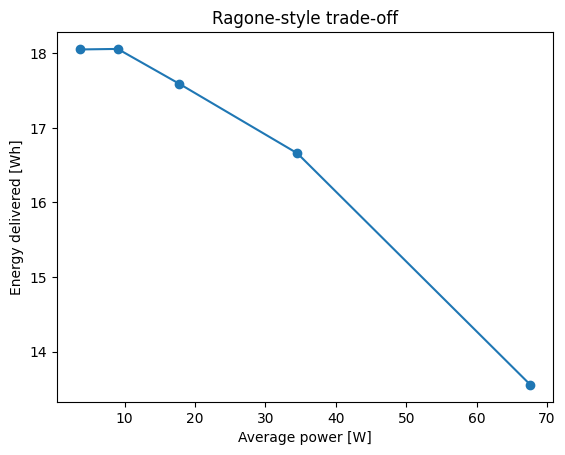

   c_rate  energy_wh  avg_power_w
0     0.2  18.049943     3.609989
1     0.5  18.057158     9.028579
2     1.0  17.591176    17.749640
3     2.0  16.658175    34.544703
4     4.0  13.555828    67.652337


In [9]:
ragone_rows = []
for c_rate in [0.2, 0.5, 1, 2, 4]:
    energy_wh, avg_power_w = ragone_point(c_rate)
    ragone_rows.append({"c_rate": c_rate, "energy_wh": energy_wh, "avg_power_w": avg_power_w})
ragone_df = pd.DataFrame(ragone_rows)

plt.figure()
plt.plot(ragone_df["avg_power_w"], ragone_df["energy_wh"], "o-")
plt.xlabel("Average power [W]")
plt.ylabel("Energy delivered [Wh]")
plt.title("Ragone-style trade-off")
plt.show()
print(ragone_df)

#### Problem 5: Cycle-life extrapolation to 80% SOH

Capacity fade is usually fit to an empirical power law
$Q(\%) = 100 - a \cdot n^{b}$ and extrapolated to find the warranty-relevant cycle
count. Complete `fade_model`; the test cell fits it to a synthetic cycle-life dataset
(standing in for a real bench export) with `scipy.optimize.curve_fit`, then
root-finds the cycle number where capacity crosses 80% with `brentq`.

In [ ]:
def fade_model(cycle, a, b):
    # TODO: return 100 - a * cycle**b
    return 100 - a - b * cycle


# Synthetic cycle-life data standing in for a real test-bench export
_rng = np.random.default_rng(42)
cycles_measured = np.arange(50, 1001, 50)
capacity_pct_measured = (
    100 - 0.08 * cycles_measured**0.55 + _rng.normal(0, 0.3, size=cycles_measured.shape)
)

_Run the cell below, then compare your printed output to the target output already shown beneath it._

Fitted fade model: capacity% = 100 - 0.1030 * cycle^0.5107
Projected cycles to 80% SOH: 30291


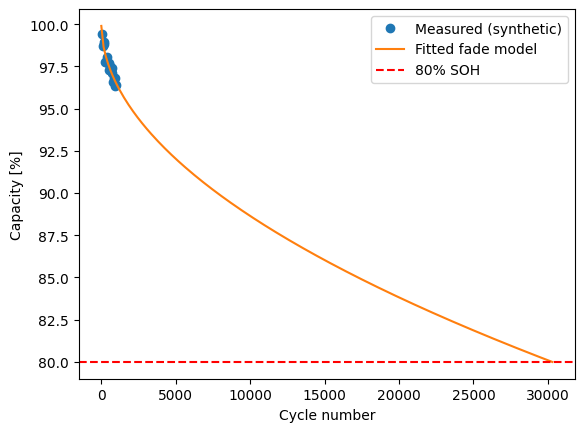

In [11]:
popt, _ = curve_fit(fade_model, cycles_measured, capacity_pct_measured, p0=[0.1, 0.5])
print(f"Fitted fade model: capacity% = 100 - {popt[0]:.4f} * cycle^{popt[1]:.4f}")

cycle_to_80pct = brentq(lambda c: fade_model(c, *popt) - 80, 1, 1e6)
print(f"Projected cycles to 80% SOH: {cycle_to_80pct:.0f}")

plt.figure()
plt.plot(cycles_measured, capacity_pct_measured, "o", label="Measured (synthetic)")
fit_cycles = np.linspace(1, cycle_to_80pct, 200)
plt.plot(fit_cycles, fade_model(fit_cycles, *popt), label="Fitted fade model")
plt.axhline(80, color="red", linestyle="--", label="80% SOH")
plt.xlabel("Cycle number")
plt.ylabel("Capacity [%]")
plt.legend()
plt.show()

#### Problem 6: Monte Carlo tolerance stack-up and capacity yield

Electrode thickness varies from coat to coat. Given a manufacturing tolerance,
Monte Carlo sampling turns that tolerance into a predicted *yield* against a capacity
spec — the simulation equivalent of a process-capability (Cpk-style) study. Complete
`estimate_yield`, which the test cell applies to 30 randomly sampled designs.

In [ ]:
def sample_capacity(pos_thickness_m, neg_thickness_m, c_rate=1.0):
    params = pybamm.ParameterValues("Chen2020")
    params["Positive electrode thickness [m]"] = pos_thickness_m
    params["Negative electrode thickness [m]"] = neg_thickness_m
    nominal_capacity = params["Nominal cell capacity [A.h]"]
    params["Current function [A]"] = nominal_capacity * c_rate
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    sol = sim.solve([0, 3600 / c_rate])
    return sol["Discharge capacity [A.h]"].data[-1]


def estimate_yield(capacities_ah, spec_min_ah):
    # TODO: return the fraction of capacities_ah that are >= spec_min_ah
    return 0.0

_Run the cell below, then compare your printed output to the target output already shown beneath it._

In [13]:
rng = np.random.default_rng(0)
params0 = pybamm.ParameterValues("Chen2020")
base_pos_thickness = params0["Positive electrode thickness [m]"]
base_neg_thickness = params0["Negative electrode thickness [m]"]

n_samples = 30
pos_samples = rng.normal(base_pos_thickness, 0.03 * base_pos_thickness, n_samples)
neg_samples = rng.normal(base_neg_thickness, 0.03 * base_neg_thickness, n_samples)
capacities_ah = np.array(
    [sample_capacity(pt, nt) for pt, nt in zip(pos_samples, neg_samples)]
)

print(f"Mean capacity: {capacities_ah.mean():.4f} Ah, std: {capacities_ah.std():.4f} Ah")
print(f"Fraction meeting >= 4.8 Ah spec: {estimate_yield(capacities_ah, 4.8):.3f}")

Mean capacity: 4.9417 Ah, std: 0.0825 Ah
Fraction meeting >= 4.8 Ah spec: 0.867


## Further reading
- [PyBaMM: Electrode State of Health reference](https://docs.pybamm.org/en/latest/source/api/models/submodels/electrode_soh.html)
- [PyBaMM: Experiment reference](https://docs.pybamm.org/en/latest/source/api/experiment/experiment.html)
- [PyBaMM documentation home](https://docs.pybamm.org/)
- [SciPy optimize reference (curve_fit, brentq)](https://docs.scipy.org/doc/scipy/reference/optimize.html)
- [PyBOP (parameter estimation / optimisation for PyBaMM)](https://github.com/pybop-team/PyBOP)